# LL vertex reconstruction efficiency

Run the imports and function definitions once. Then edit the configuration in the **Run analysis** cell and rerun that same cell. It reloads the `.coffea` file and recalculates numerator, denominator, and both plots together. There are no saved count lists or previous result arrays to reuse.

The file contains already-produced histograms: this notebook cannot regenerate events or change selections used when producing that file. If those selections changed, regenerate the `.coffea` file first.


In [1]:
%load_ext autoreload
%autoreload 2
import sys
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
import hist.intervals

sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools


## Functions
Run this cell once before running the analysis.


In [2]:
def read_counts(sig_histo, points, variable, cut, year):
    """Extract and combine only the requested samples, using local variables."""
    arrays = []
    pt_edges = vxy_edges = None
    for m1, delta, ctau in points:
        # Retain the existing project's histogram selection through plotTools.
        # Each extraction gets its own axes (no overlaid sample plots).
        fig, ax = plt.subplots(figsize=(7, 7))
        plot_dict = {'variable': variable, 'cut': cut, 'year': year}
        style = {
            'fig': fig, 'ax': ax, 'xrebin': None, 'yrebin': None,
            'xlim': None, 'ylim': None, 'doLogy': False,
            'doLogx': False, 'doLogz': False,
            'xlabel': 'Gen vertex pT (GeV)', 'ylabel': 'Gen vertex vxy (cm)',
            'zlabel': 'Counts', 'flow': None, 'doSave': False,
            'outDir': './plots', 'outName': 'unused.png'
        }
        try:
            result = ptools.plot_signal_2D(
                sig_histo, m1, delta, ctau, plot_dict, style
            )
            counts = np.asarray(result[0], dtype=float)
            xedges = np.asarray(result[1], dtype=float)
            yedges = np.asarray(result[2], dtype=float)
        #     if counts.shape != (len(xedges) - 1, len(yedges) - 1):
        #         raise ValueError(f'Unexpected histogram shape for {variable}: {counts.shape}')
        #     if not np.all(np.isfinite(counts)) or np.any(counts < 0):
        #         raise ValueError(f'Nonfinite or negative counts in {variable}')
        #     if pt_edges is None:
        #         pt_edges, vxy_edges = xedges, yedges
        #     elif not (np.array_equal(pt_edges, xedges)
        #               and np.array_equal(vxy_edges, yedges)):
        #         raise ValueError('Cannot combine samples with different bin edges.')
        #     arrays.append(counts)
        #     print(f'{variable}: m1={m1}, delta={delta}, ctau={ctau}: sum={counts.sum():g}')
        # finally:
        #     plt.close(fig)
    return np.sum(np.stack(arrays), axis=0), pt_edges, vxy_edges


# def plot_efficiency(efficiency, pt_edges, vxy_edges, label, percent=False):
#     fig, ax = plt.subplots(figsize=(10, 8))
#     mesh = ax.pcolormesh(pt_edges, vxy_edges, efficiency.T,
#                          cmap='viridis', shading='auto', vmin=0, vmax=1)
#     fig.colorbar(mesh, ax=ax).set_label('LL vertex reconstruction efficiency')
#     pt_centers = (pt_edges[:-1] + pt_edges[1:]) / 2
#     vxy_centers = (vxy_edges[:-1] + vxy_edges[1:]) / 2
#     for i, x in enumerate(pt_centers):
#         for j, y in enumerate(vxy_centers):
#             value = efficiency[i, j]
#             if np.isfinite(value):
#                 text = f'{100 * value:.2f}%' if percent else f'{value:.3f}'
#                 ax.text(x, y, text, ha='center', va='center', fontsize=10,
#                         color='white' if value < 0.5 else 'black')
#     ax.set_xticks(pt_centers)
#     ax.set_xticklabels([
#         rf'${lo:g} \leq p_{{T}}(ee) < {hi:g}$ GeV'
#         for lo, hi in zip(pt_edges[:-1], pt_edges[1:])
#     ], rotation=45, ha='right')
#     ax.set_yticks(vxy_centers)
#     ax.set_yticklabels([
#         rf'${lo:g} \leq L_{{xy}}(ee) < {hi:g}$ cm'
#         for lo, hi in zip(vxy_edges[:-1], vxy_edges[1:])
#     ])
#     ax.set_title('(Lpt, Lpt)\n' + label)
#     fig.tight_layout()
#     plt.show()


def run_ll_analysis(f_sig, samples, cut='cut1', year=2022):
    """Reload, calculate, and plot from scratch on every call; no global results."""
    points = [(m1, delta, ctau)
              for m1, deltas in samples.items()
              for delta, ctaus in deltas.items() for ctau in ctaus]
    # if not points:
    #     raise ValueError('Choose at least one sample.')
    # if len(points) != len(set(points)):
    #     raise ValueError('Duplicate sample points would double-count events.')
    print('Loading fresh histograms from:', f_sig)
    print('Selected (m1, delta, ctau):', points)
    print(f'Cut: {cut}; year: {year}')
    sig_histo = util.load(f_sig)[0]
    numerator, pt_edges, vxy_edges = read_counts(
        sig_histo, points, 'genvtx_pt_vxy', cut, year)
    denominator, den_pt_edges, den_vxy_edges = read_counts(
        sig_histo, points, 'genvtx_pt_vxy_den', cut, year)
    # if not (np.array_equal(pt_edges, den_pt_edges)
    #         and np.array_equal(vxy_edges, den_vxy_edges)):
    #     raise ValueError('Numerator and denominator bin edges differ.')
    if np.any(numerator > denominator):
        raise ValueError('Numerator exceeds denominator. Check histogram definitions/selections.')
    if denominator.sum() == 0:
        raise ValueError('Selected samples have no denominator entries.')
    valid = denominator > 0
    efficiency = np.divide(numerator, denominator,
                           out=np.full_like(numerator, np.nan), where=valid)
    uncertainty = np.full((2,) + numerator.shape, np.nan)
    uncertainty[:, valid] = hist.intervals.ratio_uncertainty(
        numerator[valid], denominator[valid], 'efficiency')
    print('Numerator counts (pT rows, Lxy columns):\n', numerator)
    print('Denominator counts (pT rows, Lxy columns):\n', denominator)
    print('Efficiency:\n', efficiency)
    print('Uncertainty [lower, upper]:\n', uncertainty)
    print(f'Combined efficiency in displayed bins: {numerator.sum()/denominator.sum():.4f}')
    label = '; '.join(f'm1={m1}, delta={delta}, ctau={ctau}'
                      for m1, delta, ctau in points)
    plot_efficiency(efficiency, pt_edges, vxy_edges, label)
    plot_efficiency(efficiency, pt_edges, vxy_edges, label, percent=True)


## Run analysis
Edit and rerun the cell below whenever you change the file, sample points, cut, or year. Empty denominator bins are left blank. Uncertainties assume numerator entries are a subset of denominator entries and the inputs are appropriate for binomial efficiency intervals.


Loading fresh histograms from: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/VertexEffLL.coffea
Selected (m1, delta, ctau): [(10, 0.2, 100), (50, 0.2, 100), (100, 0.2, 100)]
Cut: cut2; year: 2022
genvtx_pt_vxy: m1=10, delta=0.2, ctau=100: sum=4063
genvtx_pt_vxy: m1=50, delta=0.2, ctau=100: sum=984
genvtx_pt_vxy: m1=100, delta=0.2, ctau=100: sum=427
genvtx_pt_vxy_den: m1=10, delta=0.2, ctau=100: sum=43790
genvtx_pt_vxy_den: m1=50, delta=0.2, ctau=100: sum=8936
genvtx_pt_vxy_den: m1=100, delta=0.2, ctau=100: sum=3428
Numerator counts (pT rows, Lxy columns):
 [[   2.    4.    0.    0.    0.]
 [ 106.  199.  113.   41.   18.]
 [ 519. 1152.  658.  284.  159.]
 [ 421.  904.  500.  241.  153.]]
Denominator counts (pT rows, Lxy columns):
 [[ 178.  592.  591.  431.  351.]
 [ 845. 2786. 2659. 2207. 1928.]
 [1989. 7019. 7217. 6184. 5406.]
 [1187. 4159. 4149. 3383. 2893.]]
Efficiency:
 [[0.01123596 0.00675676 0.         0.         0.      

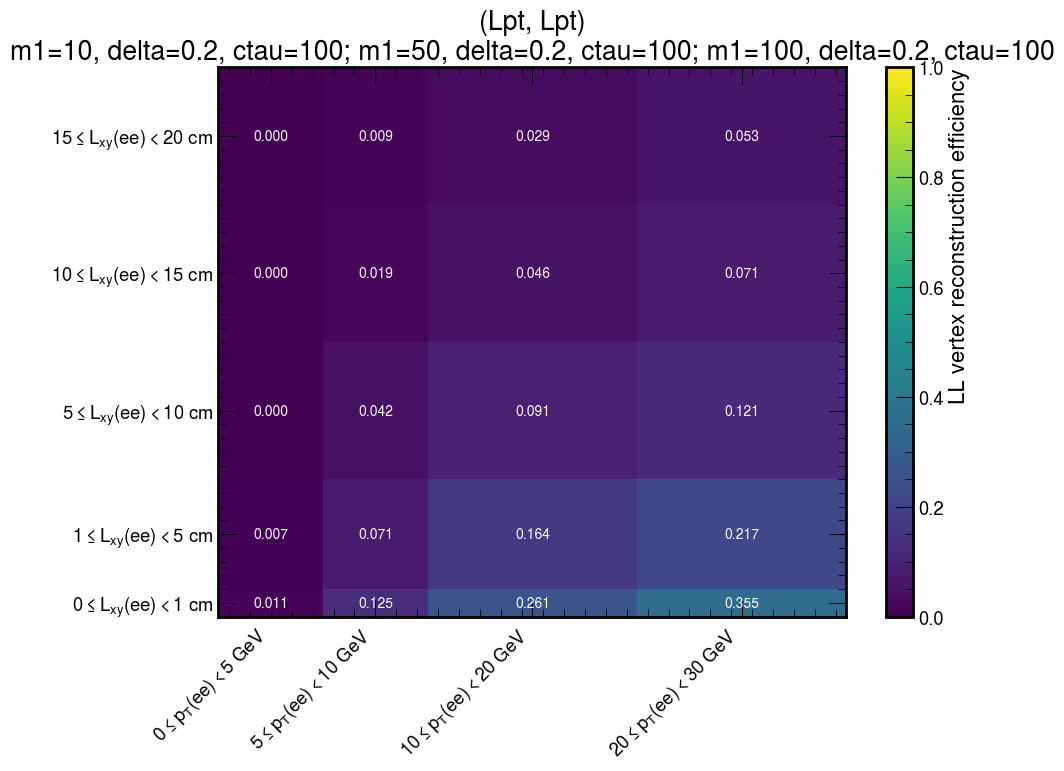

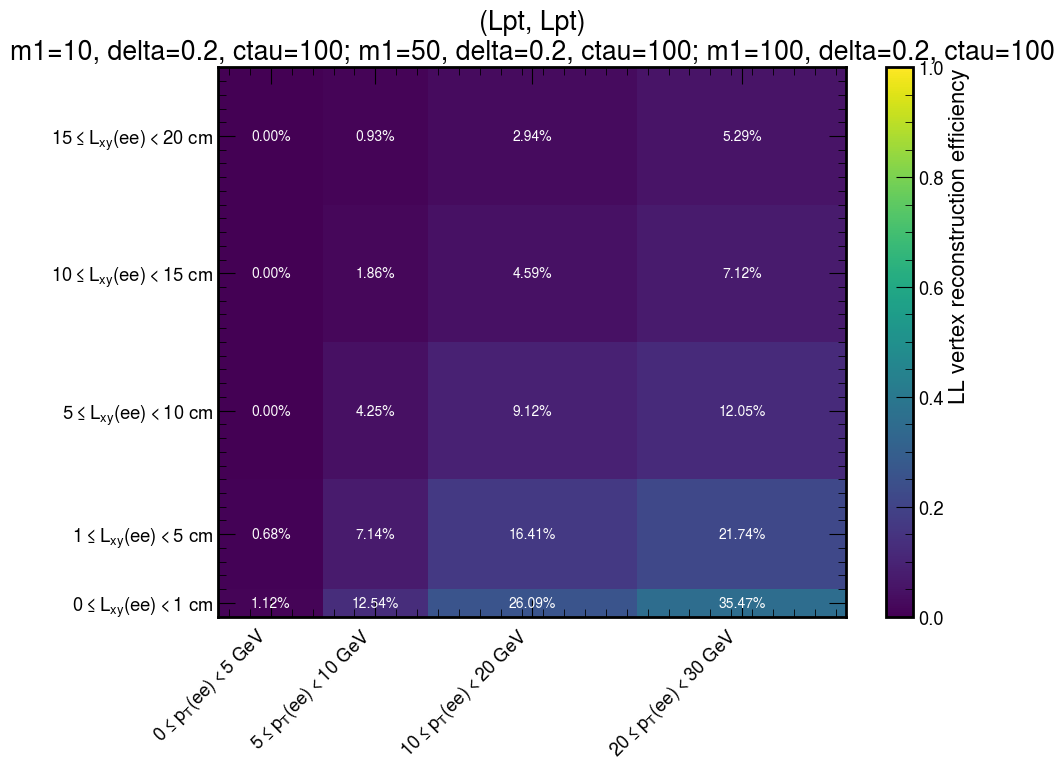

In [3]:
# RUN ANALYSIS: edit this configuration, then rerun THIS cell.
# Both counts and both plots refresh together.
plt.close('all')

f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/VertexEffLL.coffea"


# Preserves your current selection. For just one sample, remove 50 and 100.
samples = {
    10: {0.2: [100]},
    50: {0.2: [100]},
    100: {0.2: [100]},
}

run_ll_analysis(f_sig, samples, cut='cut2', year=2022)
